In [53]:
## Importing packages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline


### Importing data

In [54]:
df = pd.read_parquet("fraud_features_cleaned.parquet",engine="fastparquet")

In [55]:
df.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Is_Fraud,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,29.238259,1,1771,0,30.985221,1,1,2,27.647835,0,0,0,1,0,0,0.005464,0.0,2.0
1,717.843218,0,1487,0,17.942120,1,0,3,797.821172,0,0,0,0,0,1,0.016373,0.0,2.0
2,572.436291,4,1736,0,41.518005,1,2,5,519.277405,0,0,0,0,1,0,0.012047,0.0,2.0
3,19.882388,3,242,0,1.096487,1,0,2,21.100069,0,0,0,0,0,1,0.016563,0.0,2.0
4,109.195865,3,1060,1,32.611307,1,0,2,128.525243,0,0,0,1,0,0,0.010643,0.0,2.0


### EDA

In [56]:
df.dtypes

Transaction_Amount_USD       float64
Merchant_Category              int64
Account_Age_Days               int64
Failed_Login_Attempts          int64
Distance_From_Home_Miles     float64
IP_Country_Match               int64
Transaction_Velocity_1hr       int64
Transaction_Velocity_24hr      int64
Avg_Amount_24hr_USD          float64
Is_Weekend                     int64
Is_Fraud                       int64
Android                        int64
Linux                          int64
Windows                        int64
iOS                            int64
Merchant_ID_TE               float64
Hour                         float64
Day_of_Week                  float64
dtype: object

In [57]:
df.isnull().sum()

Transaction_Amount_USD           0
Merchant_Category                0
Account_Age_Days                 0
Failed_Login_Attempts            0
Distance_From_Home_Miles         0
IP_Country_Match                 0
Transaction_Velocity_1hr         0
Transaction_Velocity_24hr        0
Avg_Amount_24hr_USD              0
Is_Weekend                       0
Is_Fraud                         0
Android                          0
Linux                            0
Windows                          0
iOS                              0
Merchant_ID_TE                   0
Hour                         50000
Day_of_Week                  50000
dtype: int64

In [58]:
df.columns

Index(['Transaction_Amount_USD', 'Merchant_Category', 'Account_Age_Days',
       'Failed_Login_Attempts', 'Distance_From_Home_Miles', 'IP_Country_Match',
       'Transaction_Velocity_1hr', 'Transaction_Velocity_24hr',
       'Avg_Amount_24hr_USD', 'Is_Weekend', 'Is_Fraud', 'Android', 'Linux',
       'Windows', 'iOS', 'Merchant_ID_TE', 'Hour', 'Day_of_Week'],
      dtype='str')

In [59]:
df.shape

(500000, 18)

In [60]:
df.describe()

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Is_Fraud,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
count,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.00000,500000.000000,500000.000000,450000.000000,450000.000000
mean,488.634138,2.152050,898.871902,0.230396,14.894328,0.899952,1.054702,3.110570,481.251277,0.285018,0.011972,0.400650,0.050368,0.09991,0.449072,0.011972,11.491038,2.992920
std,1220.270661,1.108838,519.897860,0.675827,14.871308,0.300064,0.977887,1.967153,965.915270,0.451423,0.108760,0.490031,0.218703,0.29988,0.497400,0.004700,6.924244,1.995414
min,5.000484,0.000000,0.000000,0.000000,0.000053,0.000000,0.000000,0.000000,4.015665,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000203,0.000000,0.000000
25%,25.424785,2.000000,448.000000,0.000000,4.401824,1.000000,0.000000,2.000000,25.162453,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.008827,5.000000,1.000000
50%,60.180208,2.000000,899.000000,0.000000,10.385838,1.000000,1.000000,3.000000,59.891629,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.011788,11.000000,3.000000
75%,261.894909,3.000000,1349.000000,0.000000,20.442562,1.000000,2.000000,4.000000,261.428903,1.000000,0.000000,1.000000,0.000000,0.00000,1.000000,0.014790,17.000000,5.000000
max,99113.203087,4.000000,1799.000000,5.000000,200.316610,1.000000,9.000000,20.000000,5990.378118,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,0.028632,23.000000,6.000000


In [61]:
df['Merchant_Category'].isnull().sum()

np.int64(0)

In [62]:
df.isnull().sum()

Transaction_Amount_USD           0
Merchant_Category                0
Account_Age_Days                 0
Failed_Login_Attempts            0
Distance_From_Home_Miles         0
IP_Country_Match                 0
Transaction_Velocity_1hr         0
Transaction_Velocity_24hr        0
Avg_Amount_24hr_USD              0
Is_Weekend                       0
Is_Fraud                         0
Android                          0
Linux                            0
Windows                          0
iOS                              0
Merchant_ID_TE                   0
Hour                         50000
Day_of_Week                  50000
dtype: int64

### Splitting the data in train and test

In [63]:
n = len(df)
n_test = int(n*0.2)
n_train = int(n - n_test)

In [64]:
print((n,n_test, n_train))

(500000, 100000, 400000)


In [65]:
# distributing train, test and validation datasets.
df_test = df.iloc[ : int(n_test)]
df_train = df.iloc[int(n_test) : ]

In [66]:
df_test['Hour'].isnull().sum()

np.int64(0)

In [67]:
print(f'Shape of training dataset:{df_train.shape}')
print(f'Shape of test dataset:{df_test.shape}')

Shape of training dataset:(400000, 18)
Shape of test dataset:(100000, 18)


In [68]:
# Droppping the old indixes which are saved as column.
df_test = df_test.reset_index(drop = True)
df_train = df_train.reset_index(drop =True)

In [69]:
df_test.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Is_Fraud,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,29.238259,1,1771,0,30.985221,1,1,2,27.647835,0,0,0,1,0,0,0.005464,0.0,2.0
1,717.843218,0,1487,0,17.942120,1,0,3,797.821172,0,0,0,0,0,1,0.016373,0.0,2.0
2,572.436291,4,1736,0,41.518005,1,2,5,519.277405,0,0,0,0,1,0,0.012047,0.0,2.0
3,19.882388,3,242,0,1.096487,1,0,2,21.100069,0,0,0,0,0,1,0.016563,0.0,2.0
4,109.195865,3,1060,1,32.611307,1,0,2,128.525243,0,0,0,1,0,0,0.010643,0.0,2.0


### splliting the data x, y 

In [45]:
y_train = df_train['Is_Fraud']
y_test = df_test['Is_Fraud']

In [70]:
X_train = df_train.drop(columns=['Is_Fraud'])
X_test = df_test.drop(columns=['Is_Fraud'])

In [71]:
X_train

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,58.204133,2,1486,0,12.345333,1,1,2,59.323300,0,1,0,0,0,0.028632,NaN,NaN
1,95.663186,3,962,0,12.127783,1,1,1,76.740279,0,0,0,0,1,0.017358,NaN,NaN
2,8.266796,2,1652,0,1.307577,1,0,1,7.776989,0,0,0,0,1,0.012447,NaN,NaN
3,16.124125,2,1567,0,10.940974,1,1,1,17.606635,0,0,1,0,0,0.007304,NaN,NaN
4,157.793924,2,1737,0,9.322771,1,1,4,135.264274,0,0,0,0,1,0.012669,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,6.217553,3,1401,0,0.865180,1,0,3,6.206533,0,1,0,0,0,0.008533,23.0,2.0
399996,39.252568,3,976,0,3.700393,1,1,2,34.921098,0,0,0,0,1,0.010515,23.0,2.0
399997,15.572066,2,1200,0,15.044283,1,2,4,18.540503,0,1,0,0,0,0.010851,23.0,2.0
399998,96.120914,2,1183,1,6.146887,1,0,2,95.674461,0,0,0,0,1,0.008393,23.0,2.0


In [72]:
print(f'Shape of X_train, y_train: {(X_train.shape, y_train.shape)}')
print(f'Shape of X_test, y_test: {(X_test.shape, y_test.shape)}')

Shape of X_train, y_train: ((400000, 17), (400000,))
Shape of X_test, y_test: ((100000, 17), (100000,))


In [73]:
X_train.head(10)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,58.204133,2,1486,0,12.345333,1,1,2,59.323300,0,1,0,0,0,0.028632,NaN,NaN
1,95.663186,3,962,0,12.127783,1,1,1,76.740279,0,0,0,0,1,0.017358,NaN,NaN
2,8.266796,2,1652,0,1.307577,1,0,1,7.776989,0,0,0,0,1,0.012447,NaN,NaN
3,16.124125,2,1567,0,10.940974,1,1,1,17.606635,0,0,1,0,0,0.007304,NaN,NaN
4,157.793924,2,1737,0,9.322771,1,1,4,135.264274,0,0,0,0,1,0.012669,NaN,NaN
5,390.201007,4,439,0,2.432670,1,2,5,347.081637,0,0,0,0,1,0.003655,NaN,NaN
6,12.576124,3,250,0,43.585686,1,0,3,12.650998,0,0,0,1,0,0.015049,NaN,NaN
7,31.729550,2,514,0,10.514360,1,2,3,28.164611,0,0,0,0,1,0.010461,NaN,NaN
8,46.544704,2,479,0,4.490672,1,1,4,41.117994,0,0,1,0,0,0.028632,NaN,NaN
9,38.305968,2,266,0,2.426142,1,1,5,37.251434,0,1,0,0,0,0.012170,NaN,NaN


In [74]:
X_train['Hour']

0          NaN
1          NaN
2          NaN
3          NaN
4          NaN
          ... 
399995    23.0
399996    23.0
399997    23.0
399998    23.0
399999    23.0
Name: Hour, Length: 400000, dtype: float64

### Filling the NaN value with 0

In [79]:
print(X_train['Hour'].dtypes)
print(X_train['Hour'].isnull().sum())

float64
50000


In [80]:
X_train['Hour'] = X_train['Hour'].fillna(0)
X_test['Hour'] = X_test['Hour'].fillna(0)

In [81]:
X_train['Day_of_Week'] = X_train['Day_of_Week'].fillna(0)
X_test['Day_of_Week'] = X_test['Day_of_Week'].fillna(0)

In [83]:
X_train.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,58.204133,2,1486,0,12.345333,1,1,2,59.323300,0,1,0,0,0,0.028632,0.0,0.0
1,95.663186,3,962,0,12.127783,1,1,1,76.740279,0,0,0,0,1,0.017358,0.0,0.0
2,8.266796,2,1652,0,1.307577,1,0,1,7.776989,0,0,0,0,1,0.012447,0.0,0.0
3,16.124125,2,1567,0,10.940974,1,1,1,17.606635,0,0,1,0,0,0.007304,0.0,0.0
4,157.793924,2,1737,0,9.322771,1,1,4,135.264274,0,0,0,0,1,0.012669,0.0,0.0


### analysis of continious variable

In [82]:
X_train.nunique().sort_values()

IP_Country_Match                  2
Linux                             2
Android                           2
iOS                               2
Windows                           2
Is_Weekend                        2
Failed_Login_Attempts             4
Merchant_Category                 5
Day_of_Week                       7
Transaction_Velocity_1hr         10
Transaction_Velocity_24hr        21
Hour                             24
Merchant_ID_TE                  576
Account_Age_Days               1800
Distance_From_Home_Miles     400000
Transaction_Amount_USD       400000
Avg_Amount_24hr_USD          400000
dtype: int64

In [86]:
X_train['Transaction_Velocity_1hr'].value_counts()

Transaction_Velocity_1hr
2    131812
1    131809
0    131805
5       814
4       810
7       801
6       774
8       561
3       477
9       337
Name: count, dtype: int64

In [87]:
X_train['Transaction_Velocity_24hr'].value_counts()

Transaction_Velocity_24hr
3     79552
2     79172
4     78778
1     52795
5     52018
6     26533
0     26472
13      510
14      506
12      502
11      476
15      435
10      427
16      411
9       354
17      295
8       240
18      190
7       188
19      111
20       35
Name: count, dtype: int64

### Applying StanderdScaling

In [88]:
continious_variable = ['Avg_Amount_24hr_USD','Transaction_Amount_USD','Distance_From_Home_Miles','Account_Age_Days','Merchant_ID_TE']

In [89]:
from sklearn.preprocessing import StandardScaler

In [90]:
scaler = StandardScaler()

In [91]:
X_train[continious_variable] = scaler.fit_transform(X_train[continious_variable])
X_test[continious_variable] = scaler.fit_transform(X_test[continious_variable])

In [92]:
print(f'Shape of X_train: {(X_train.shape)}')
print(f'Shape of X_test: {(X_test.shape)}')

Shape of X_train: (400000, 17)
Shape of X_test: (100000, 17)


In [93]:
X_train.head(5)

,Transaction_Amount_USD,Merchant_Category,Account_Age_Days,Failed_Login_Attempts,Distance_From_Home_Miles,IP_Country_Match,Transaction_Velocity_1hr,Transaction_Velocity_24hr,Avg_Amount_24hr_USD,Is_Weekend,Android,Linux,Windows,iOS,Merchant_ID_TE,Hour,Day_of_Week
0,-0.338588,2,1.129096,0,-0.175351,1,1,2,-0.436935,0,1,0,0,0,3.546253,0.0,0.0
1,-0.309267,3,0.121457,0,-0.189849,1,1,1,-0.418913,0,0,0,0,1,1.147057,0.0,0.0
2,-0.377677,2,1.448310,0,-0.910909,1,0,1,-0.490272,0,0,0,0,1,0.101952,0.0,0.0
3,-0.371527,2,1.284857,0,-0.268938,1,1,1,-0.480101,0,0,1,0,0,-0.992450,0.0,0.0
4,-0.260634,2,1.611763,0,-0.376775,1,1,4,-0.358356,0,0,0,0,1,0.149085,0.0,0.0


#### Traing the model on LR

In [94]:
# Logistic regression using scikit-learn
from sklearn.linear_model import LogisticRegression

In [115]:
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [116]:
model.intercept_[0]

np.float64(-26.032788622685484)

In [117]:
model.coef_[0].round(3)

array([-0.416, -0.241, -0.276,  0.422,  0.133, -1.272,  3.746,  3.438,
        0.185, -0.19 , -6.926, -5.368, -6.86 , -6.25 ,  0.524, -0.029,
        0.007])

In [118]:
model.predict(X_test)

array([0, 0, 0, ..., 0, 0, 0], shape=(100000,))

In [119]:
y_pred = model.predict_proba(X_test)[:,1]

In [123]:
y_pred[:10]

array([8.32913163e-11, 9.63904543e-11, 2.35505637e-05, 2.97026694e-12,
       4.81795487e-12, 1.32288319e-11, 1.38324073e-09, 1.00750917e-03,
       5.23537744e-09, 5.50285447e-09])

In [124]:
y_prediction  = (y_pred >= 0.5).astype(int)

In [125]:
from sklearn.metrics import confusion_matrix

In [127]:
confusion_matrix(y_test, y_prediction)

array([[98807,     0],
       [   16,  1177]])

### MOdel Evaluation

In [141]:
df_pred = pd.DataFrame()
df_pred['Probability'] = y_pred
df_pred['y_prediction'] = y_prediction
df_pred['Actual_Value'] = y_test
df_pred['Correct'] = (y_prediction == y_test)



In [129]:
df_pred.head()

,Probability,y_prediction,Actual_Value,Correct
0,8.329132e-11,0,0,True
1,9.639045e-11,0,0,True
2,2.355056e-05,0,0,True
3,2.970267e-12,0,0,True
4,4.817955e-12,0,0,True


In [134]:
df_pred['Correct'].value_counts()

Correct
True     99984
False       16
Name: count, dtype: int64

In [135]:
Correct_prediction = 99984
Wrong_prediction = 16
Total = Correct_prediction + Wrong_prediction

In [138]:
accuracy = (Correct_prediction/ Total)*100

In [140]:
print(f'Accuracy of the model is : {accuracy} %')

Accuracy of the model is : 99.984 %


In [142]:
TN, FP, FN, TP = confusion_matrix(y_test, y_prediction).ravel()

In [144]:
print(f' True Positive :{TP}')
print(f' True Negative :{TN}')
print(f' False Positive :{FP}')
print(f' False Negative :{FN}')


 True Positive :1177
 True Negative :98807
 False Positive :0
 False Negative :16


In [145]:
precision = TP/(TP+FP)
Recall = TP/(TP+FN)

In [146]:
print(f' Precision :{precision}')
print(f' Recall :{Recall}')

 Precision :1.0
 Recall :0.9865884325230512


In [147]:
!pip install imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---------------------------------------- 2/2 [imbalanced-learn]



### Applying smot for oversampling.

In [148]:
from imblearn.over_sampling import SMOTE

In [149]:
smote = SMOTE(random_state=42)

In [150]:
X_train_smoted,y_train_smoted = smote.fit_resample(X_train,y_train)

In [151]:
le = LogisticRegression()
le.fit(X_train_smoted, y_train_smoted)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [152]:
y_pred_smote = le.predict_proba(X_test)[:,1]

In [153]:
y_pred_smote

array([1.04214540e-12, 8.72843439e-14, 2.56615984e-04, ...,
       3.20911434e-03, 6.56829436e-09, 1.65670658e-14], shape=(100000,))

In [154]:
y_prediction_smote  = (y_pred >= 0.5).astype(int)

In [155]:
y_prediction_smote[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [158]:
X, X_, y, y_ = confusion_matrix(y_test, y_prediction_smote).ravel()

In [159]:
print(f' True Positive :{X}')
print(f' True Negative :{X_}')
print(f' False Positive :{y}')
print(f' False Negative :{y_}')


 True Positive :98807
 True Negative :0
 False Positive :16
 False Negative :1177


In [160]:
precision_smote = X/(X+y)
Recall_smote = X/(X+y_)

In [195]:
print(f'Smoted Precision :{precision_smote}')
print(f' Smoted Recall :{Recall_smote}')

Smoted Precision :0.9998380943707437
 Smoted Recall :0.9882281164986397


### APPLYING Random ForesT Classifier

In [162]:
from sklearn.ensemble import RandomForestClassifier

In [163]:
rf_model = RandomForestClassifier(n_estimators=100, random_state = 42)

In [164]:
rf_model.fit(X_train_smoted, y_train_smoted)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [166]:
y_pred_rf = rf_model.predict(X_test)

In [167]:
y_prob_rf = rf_model.predict_proba(X_test)[:,1]   

In [171]:
y_prob_rf[:10]

array([0.  , 0.  , 0.01, 0.  , 0.  , 0.  , 0.  , 0.01, 0.  , 0.01])

In [172]:
y_prediction_rf  = (y_prob_rf >= 0.5).astype(int)

In [173]:
y_prediction_rf[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

#### Model Evaluation

In [174]:
from sklearn.metrics import f1_score

In [175]:
print(f'F1-Score of Random Forest Classifier: {f1_score(y_test,y_prediction_rf)}')

F1-Score of Random Forest Classifier: 0.998320738874895


In [178]:
print(f'F1-Score of Logistic Regression: {f1_score(y_test,y_prediction_smote)}')

F1-Score of Logistic Regression: 0.9932489451476794


In [190]:
TP_rf, TN_rf, FP_rf, FN_rf = confusion_matrix(y_test,y_prediction_rf).ravel()

In [192]:
print(f' True Positive :{TP_rf}')
print(f' True Negative :{TN_rf}')
print(f' False Positive :{FP_rf}')
print(f' False Negative :{FN_rf}')

 True Positive :98807
 True Negative :0
 False Positive :4
 False Negative :1189


In [193]:
precision_rf = TP_rf/(TP_rf+FP_rf)
Recall_rf = TP_rf/(TP_rf+FN_rf)

In [194]:
print(f'Smoted Precision :{precision_rf}')
print(f' Smoted Recall :{Recall_rf}')

Smoted Precision :0.9999595186770703
 Smoted Recall :0.9881095243809752


#### ROC AND AUC curve

In [179]:
from sklearn.metrics import roc_curve, roc_auc_score

In [181]:
fpr_lr,tpr_lr,_ = roc_curve(y_test,y_pred_smote)
fpr_rf,tpr_rf,_= roc_curve(y_test,)

In [182]:
auc_lr = roc_auc_score(y_test,y_pred_smote)
auc_rf = roc_auc_score(y_test,y_pred_smote)

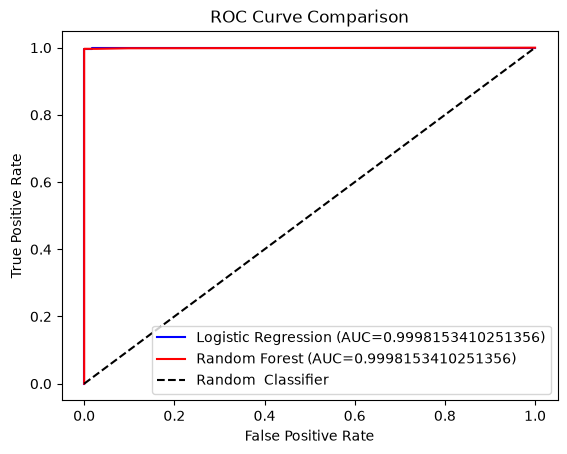

In [196]:
plt.plot(fpr_lr,tpr_lr,color='blue',label=f'Logistic Regression (AUC={auc_lr})')
plt.plot(fpr_rf,tpr_rf,color='red',label=f'Random Forest (AUC={auc_rf})')
plt.plot([0, 1],[0, 1],'k--',label='Random  Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.show()

#### Precision and Recall Graph

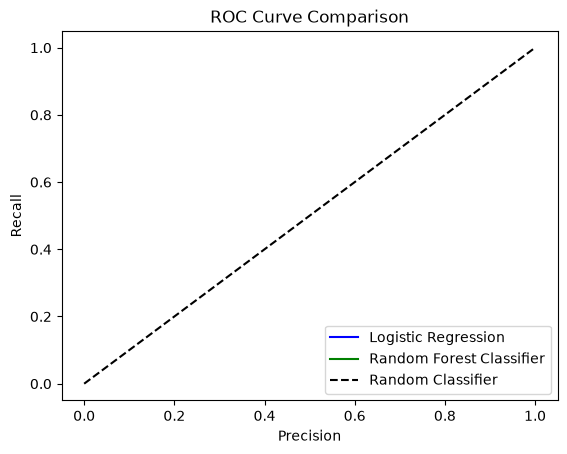

In [197]:
plt.plot(precision_smote,Recall_smote,color='blue',label=f'Logistic Regression ')
plt.plot(precision_rf,Recall_rf,color='green',label=f'Random Forest Classifier')
plt.plot([0, 1],[0, 1],'k--',label='Random Classifier')
plt.xlabel('Precision')
plt.ylabel('Recall')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.show()

### Top 10 Feature selection of Random Forest

In [199]:
important_feature = pd.DataFrame({'features':X_train.columns, 'importance':rf_model.feature_importances_})

In [203]:
top_10 = important_feature.sort_values(by='importance',ascending=False).head(10)

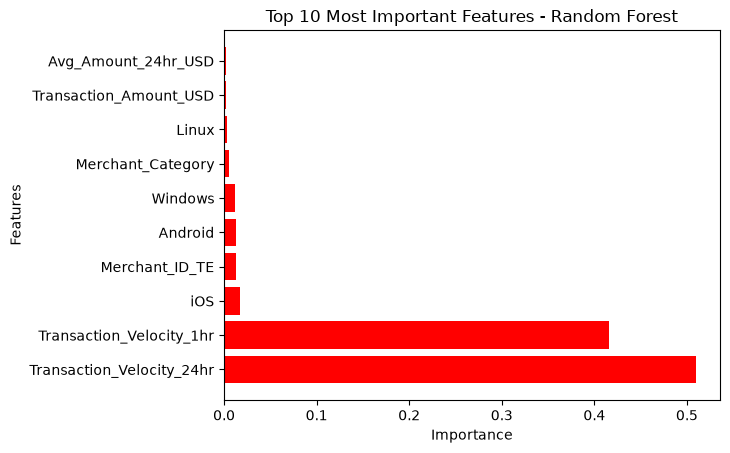

In [205]:
plt.barh(top_10['features'],top_10['importance'], color = 'red')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Top 10 Most Important Features - Random Forest')
plt.show()

### Saving the Metrices in file.

In [210]:
with open("baseline_results.txt", "w") as f:
    f.write("Baseline Model Results\n")
    f.write("=" * 40 + "\n\n")
    f.write(f"Accuracy : {accuracy:.4f}\n")
    f.write(f"Precision of Logistic Regression: {precision_smote:.4f}\n")
    f.write(f"Recall of Logistic Regression   : {Recall_smote:.4f}\n")
    f.write(f"Precision of Random Forest Classifier: {precision_rf:.4f}\n")
    f.write(f"Recall of Random Forest Classifier   : {Recall_rf:.4f}\n")
    f.write(f"F1 Score of Logistic Regression : {f1_score(y_test,y_prediction_smote):.4f}\n")
    f.write(f"F1 Score of Ramdom Forest : {f1_score(y_test,y_prediction_rf):.4f}\n")
